# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [1]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

In [2]:
#!rm SUSY.csv

In [3]:
#!gunzip SUSY.csv.gz

In [5]:
ls -lh

total 872K
-rw-r--r-- 1 ax01 ax01 357K Oct  9 13:49 Lab.7.ipynb
-rw-r--r-- 1 ax01 ax01 150K Oct  9 13:49 Lab.7.pdf
-rw-r--r-- 1 ax01 ax01 357K Oct 23 18:27 Lab.7.solution.ipynb
lrwxrwxrwx 1 ax01 ax01   17 Oct 23 18:29 SUSY-small.csv@ -> ../SUSY-small.csv
lrwxrwxrwx 1 ax01 ax01   11 Oct 23 18:29 SUSY.csv@ -> ../SUSY.csv


The data is provided as a comma separated file.

In [6]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [7]:
!ls -lh

total 872K
-rw-r--r-- 1 ax01 ax01 357K Oct  9 13:49 Lab.7.ipynb
-rw-r--r-- 1 ax01 ax01 150K Oct  9 13:49 Lab.7.pdf
-rw-r--r-- 1 ax01 ax01 358K Oct 23 18:29 Lab.7.solution.ipynb
lrwxrwxrwx 1 ax01 ax01   17 Oct 23 18:29 SUSY-small.csv -> ../SUSY-small.csv
lrwxrwxrwx 1 ax01 ax01   11 Oct 23 18:29 SUSY.csv -> ../SUSY.csv


We see that we have 5 million datapoints.

In [8]:
!wc -l SUSY.csv

5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [9]:
!head -500000 SUSY.csv > SUSY-small.csv

In [10]:
ls -lh

total 872K
-rw-r--r-- 1 ax01 ax01 357K Oct  9 13:49 Lab.7.ipynb
-rw-r--r-- 1 ax01 ax01 150K Oct  9 13:49 Lab.7.pdf
-rw-r--r-- 1 ax01 ax01 358K Oct 23 18:31 Lab.7.solution.ipynb
lrwxrwxrwx 1 ax01 ax01   17 Oct 23 18:29 SUSY-small.csv@ -> ../SUSY-small.csv
lrwxrwxrwx 1 ax01 ax01   11 Oct 23 18:29 SUSY.csv@ -> ../SUSY.csv


In [11]:
! wc -l SUSY-small.csv

500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [12]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [13]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [14]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [14]:
FeatureNames

['R',
 'dPhi_r_b',
 'MT2',
 'cos_theta_r1',
 'M_TR_2',
 'M_Delta_R',
 'MET_rel',
 'S_R',
 'M_R',
 'axial_MET']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [16]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [18]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [19]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


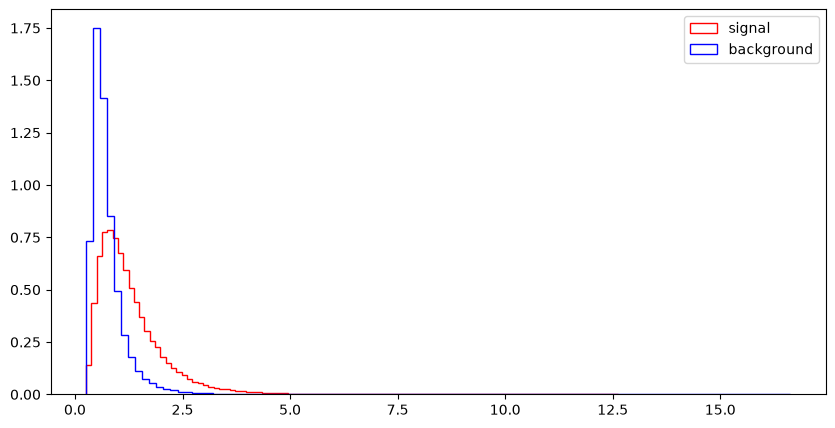

l_1_eta


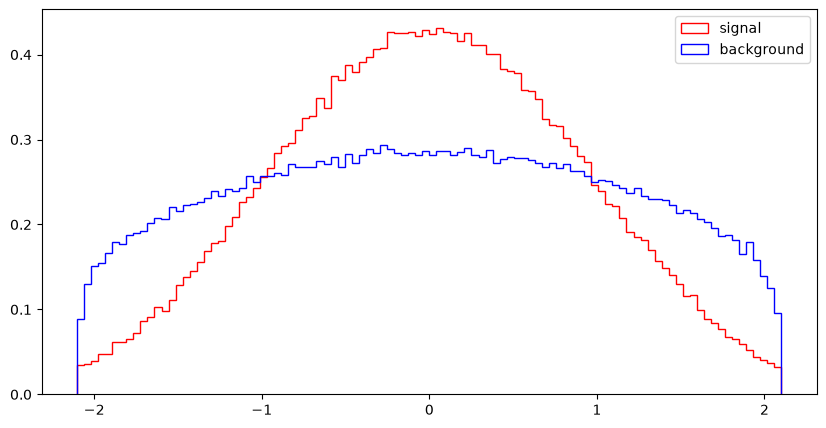

l_1_phi


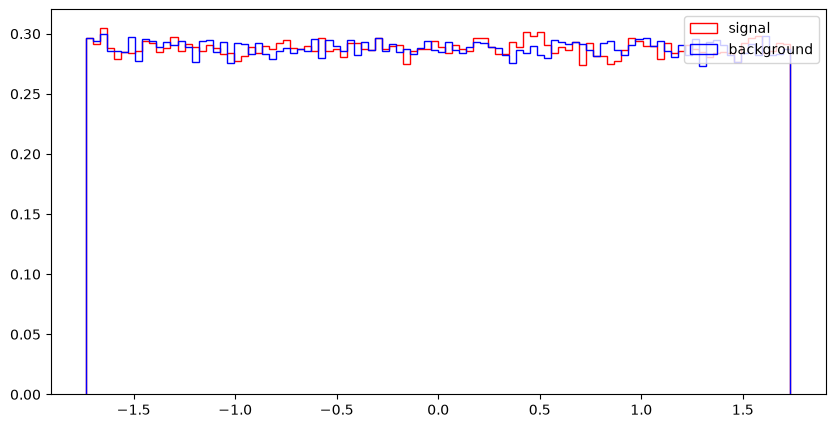

l_2_pT


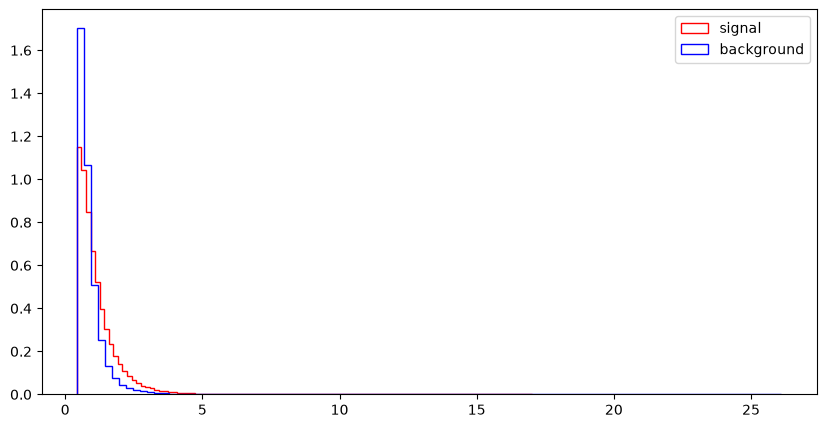

l_2_eta


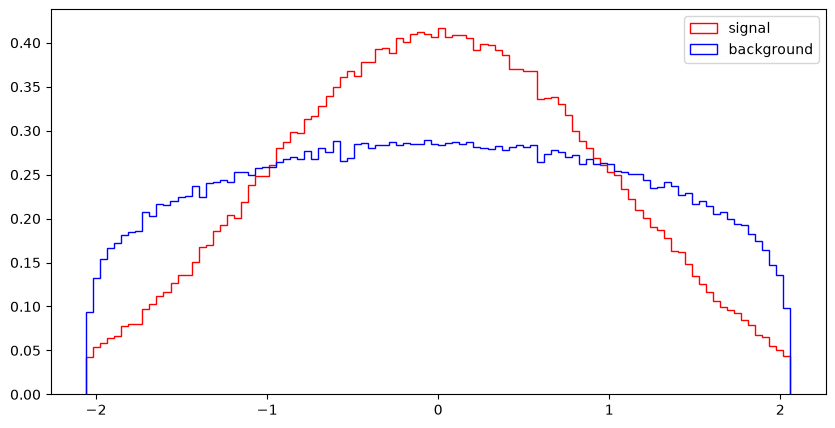

l_2_phi


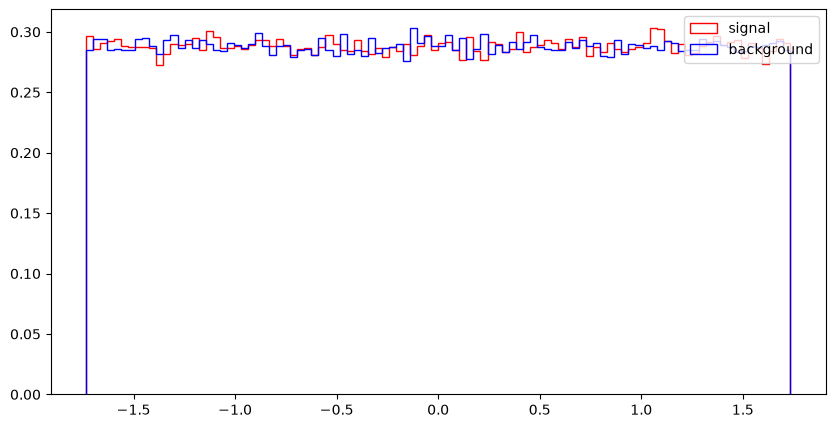

MET


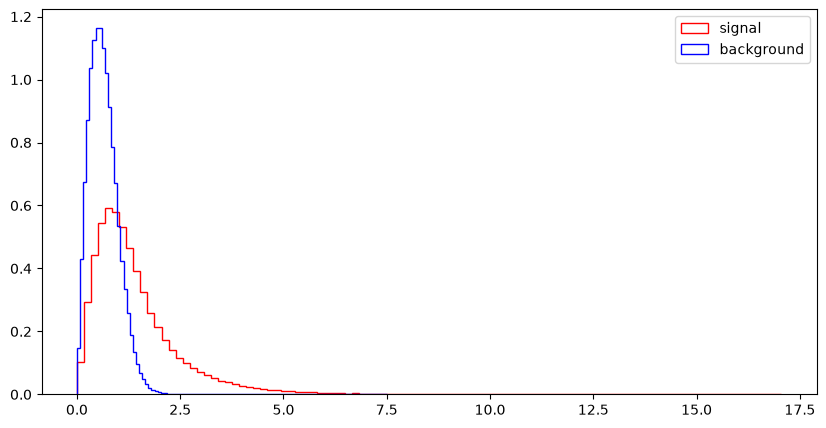

MET_phi


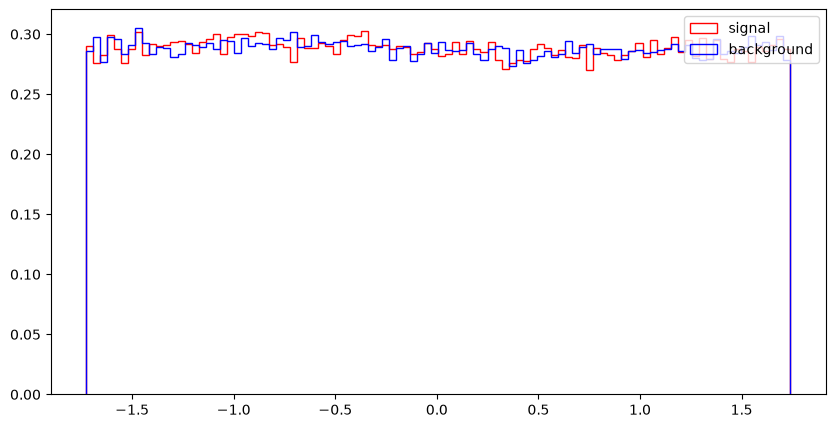

MET_rel


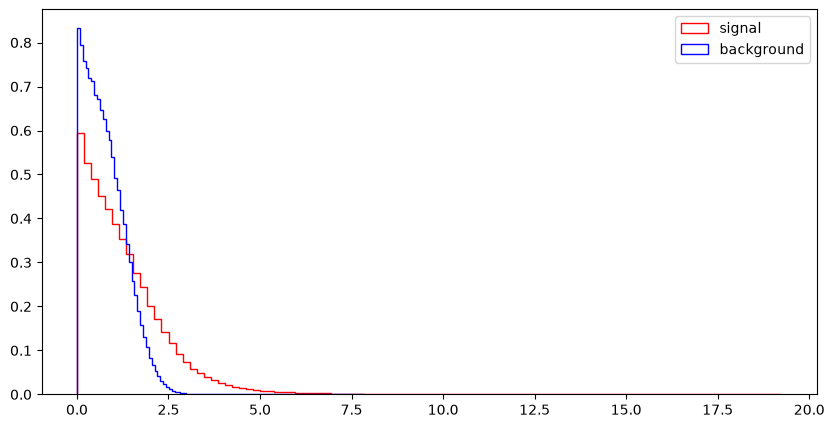

axial_MET


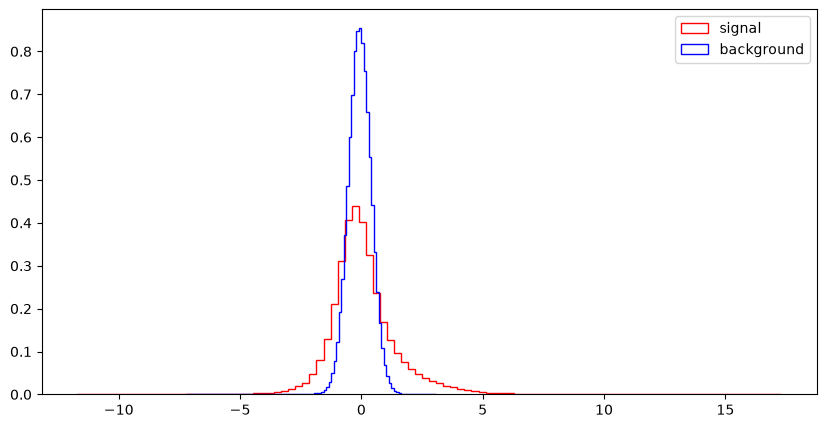

M_R


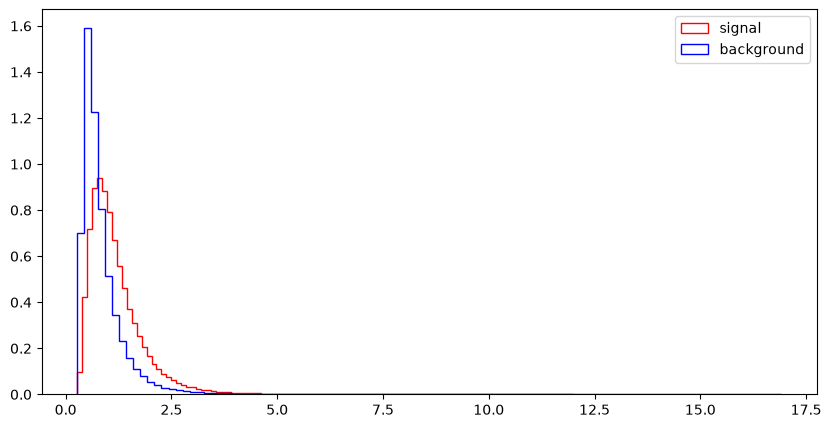

M_TR_2


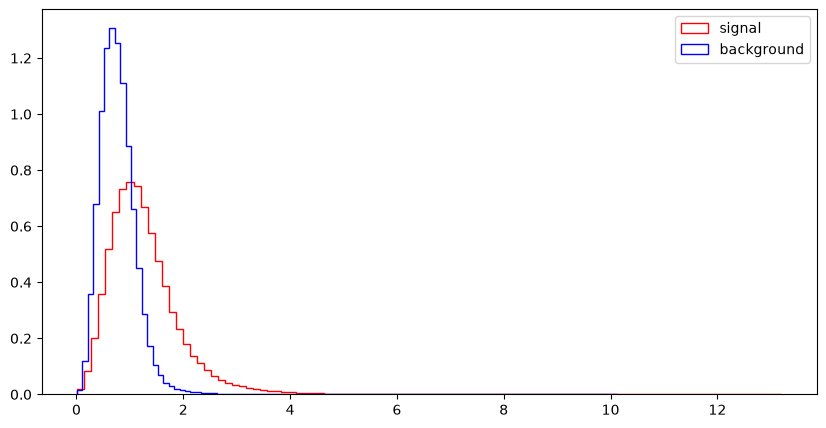

R


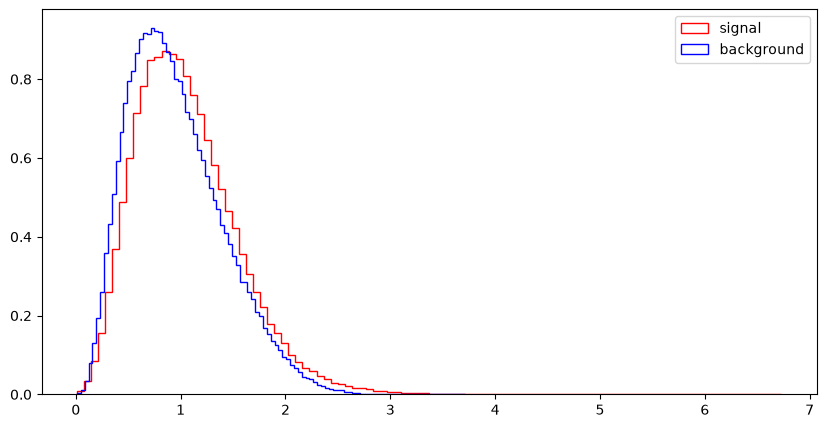

MT2


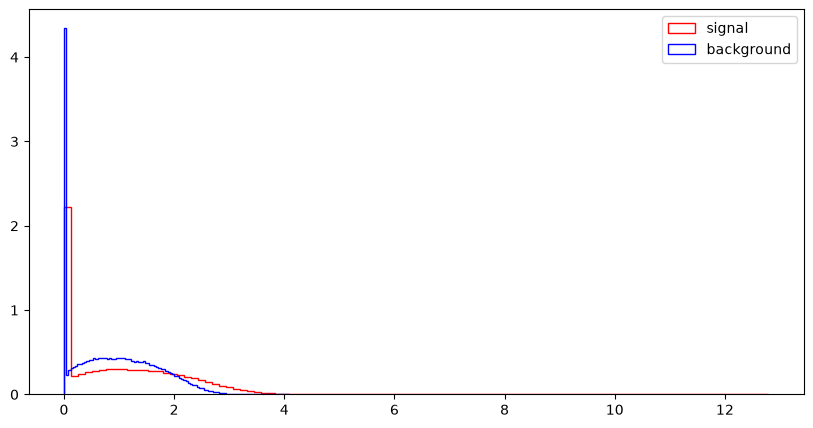

S_R


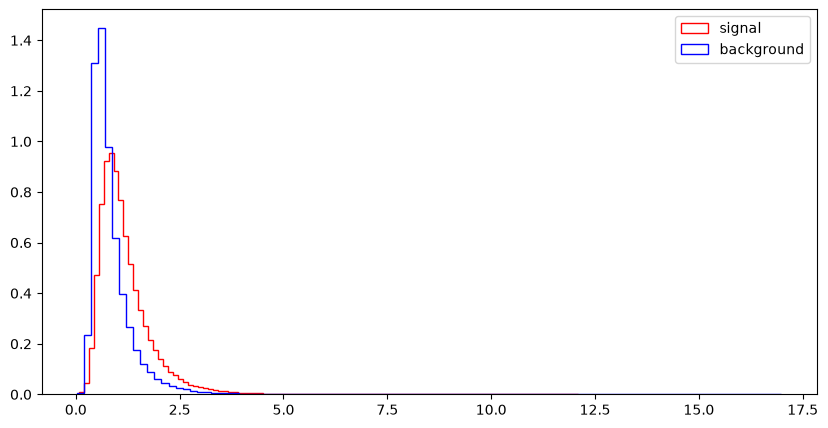

M_Delta_R


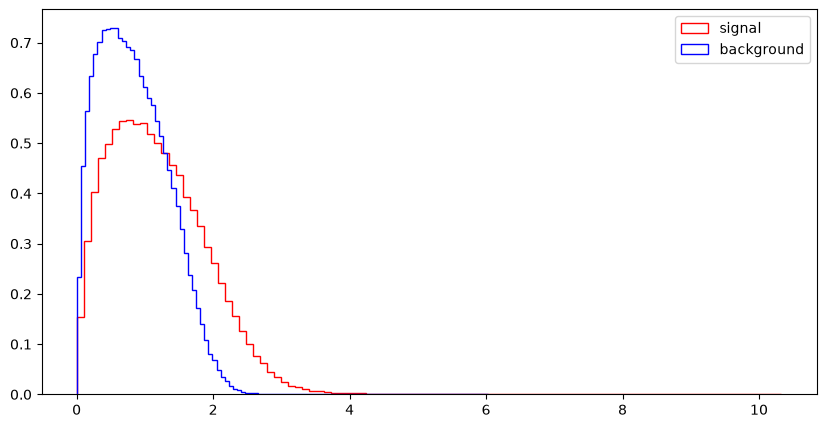

dPhi_r_b


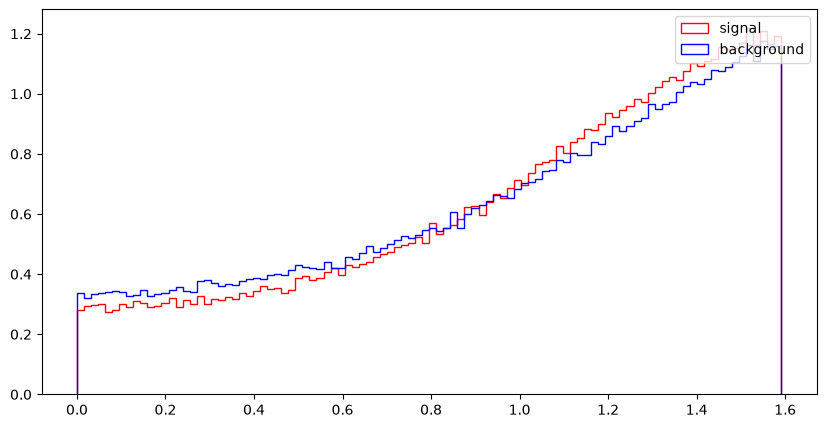

cos_theta_r1


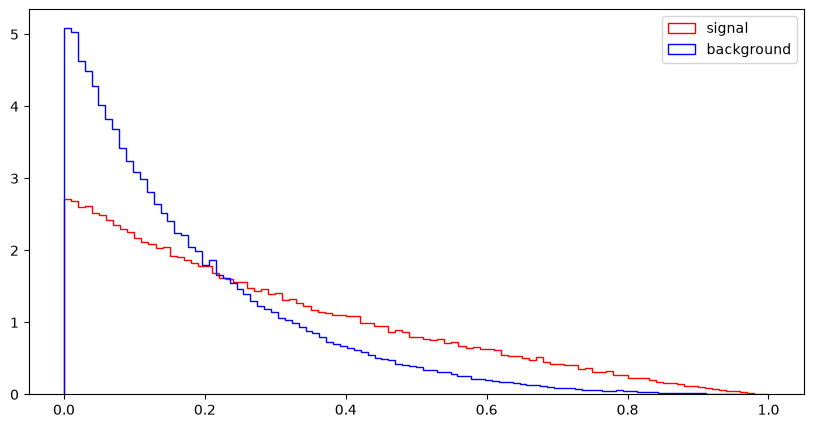

In [20]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

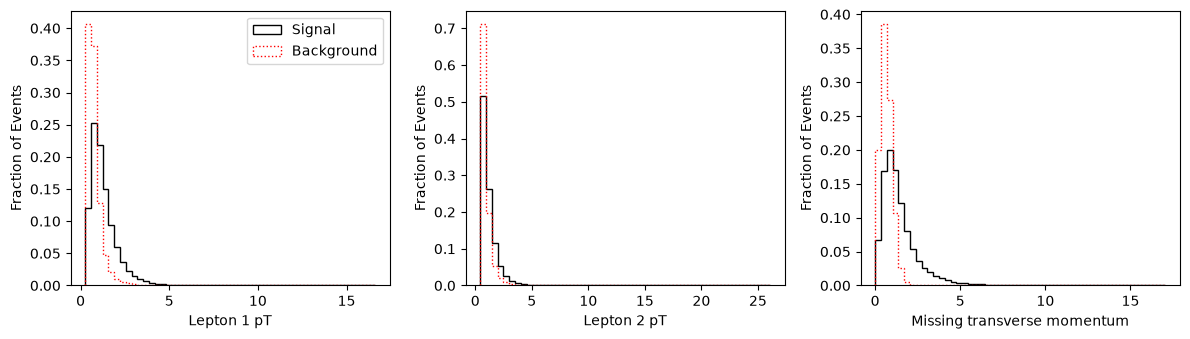

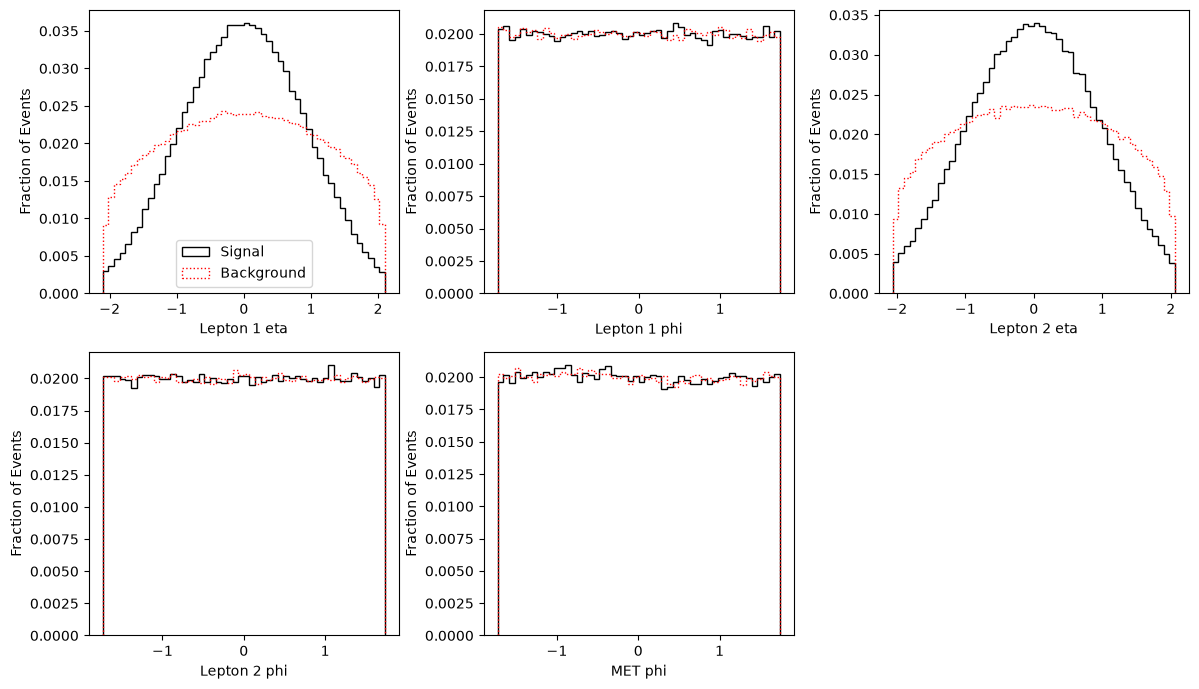

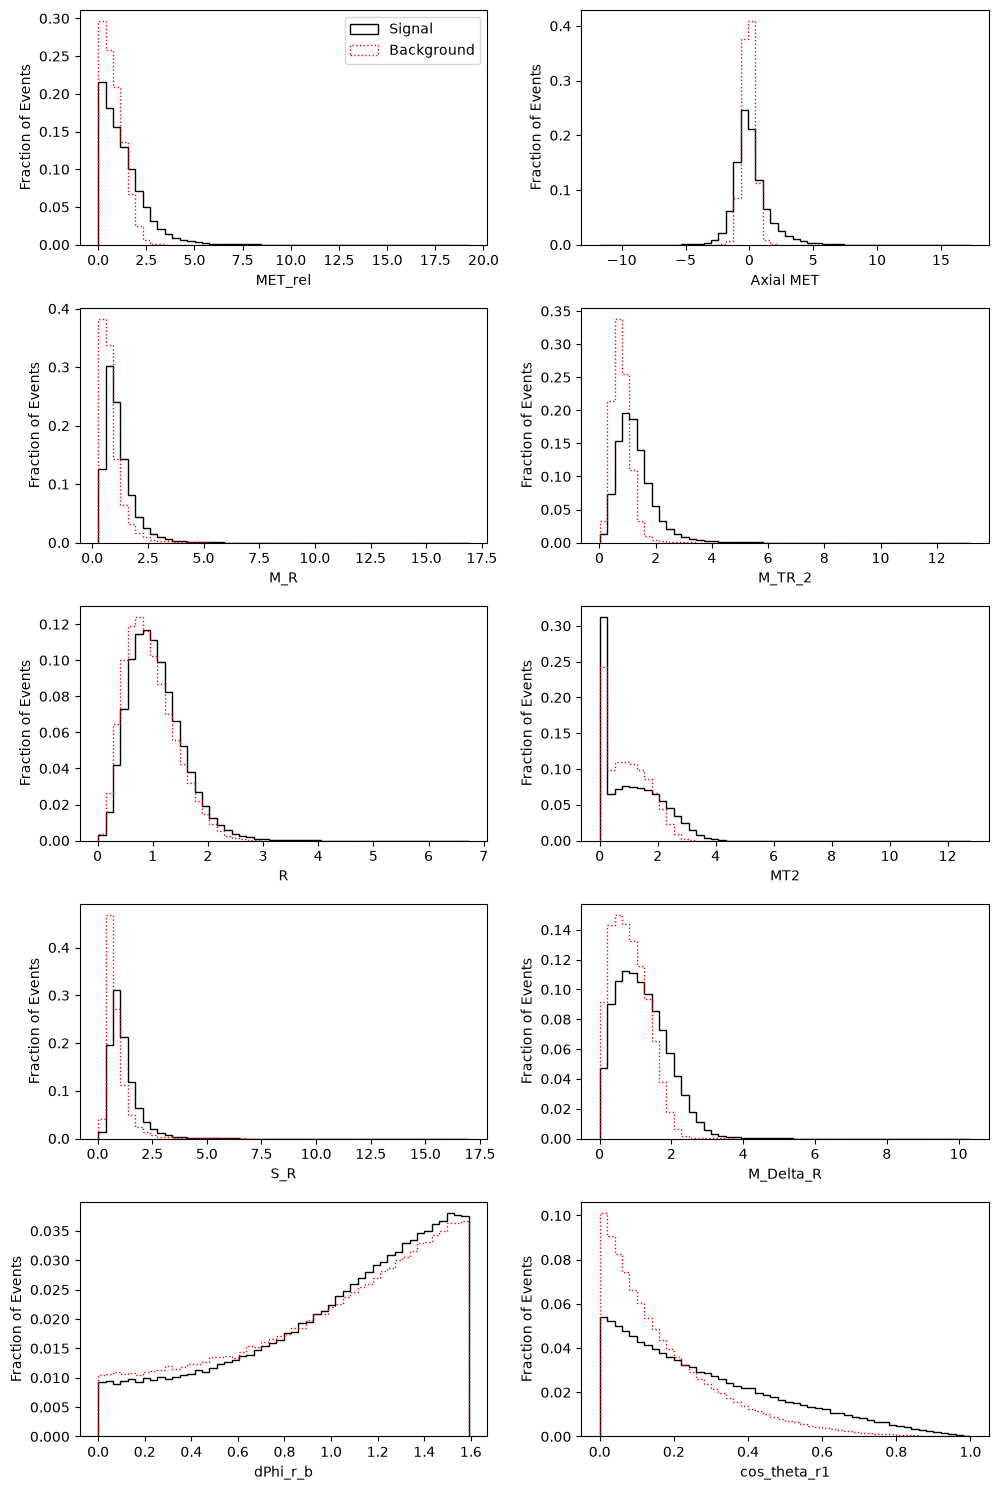

In [29]:
import numpy as np
import matplotlib.pyplot as plt

all_names = VarNames[1:]
low_names = RawNames
high_names = FeatureNames

labels = {
    "l_1_pT": "Lepton 1 pT",
    "l_2_pT": "Lepton 2 pT",
    "l_1_eta": "Lepton 1 eta",
    "l_2_eta": "Lepton 2 eta",
    "l_1_phi": "Lepton 1 phi",
    "l_2_phi": "Lepton 2 phi",
    "MET": "Missing transverse momentum",
    "MET_phi": "MET phi",
    "MET_rel": "MET_rel",
    "axial_MET": "Axial MET",
    "M_R": "M_R",
    "M_TR_2": "M_TR_2",
    "R": "R",
    "MT2": "MT2",
    "S_R": "S_R",
    "M_Delta_R": "M_Delta_R",
    "dPhi_r_b": "dPhi_r_b",
    "cos_theta_r1": "cos_theta_r1"
}

def plot_histogram(ax, variable):
    signal_values = df_sig[variable].values
    background_values = df_bkg[variable].values
    bins = np.histogram_bin_edges(
        np.concatenate([signal_values, background_values]), bins=50
    )

    ax.hist(signal_values, bins=bins,
            weights=np.ones(len(signal_values)) / len(signal_values),
            histtype="step", color="black", label="Signal")
    ax.hist(background_values, bins=bins,
            weights=np.ones(len(background_values)) / len(background_values),
            histtype="step", color="red", linestyle=":", label="Background")
    ax.set_xlabel(labels[variable])
    ax.set_ylabel("Fraction of Events")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, variable in zip(axes, ["l_1_pT", "l_2_pT", "MET"]):
    plot_histogram(ax, variable)
axes[0].legend()
fig.tight_layout()
plt.show()

other_low_names = ["l_1_eta", "l_1_phi", "l_2_eta", "l_2_phi", "MET_phi"]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, variable in zip(axes.flat, other_low_names):
    plot_histogram(ax, variable)
for ax in axes.flat[len(other_low_names):]:
    ax.axis("off")
axes[0, 0].legend()
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(5, 2, figsize=(10, 15))
for ax, variable in zip(axes.flat, high_names):
    plot_histogram(ax, variable)
axes[0, 0].legend()
fig.tight_layout()
plt.show()

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

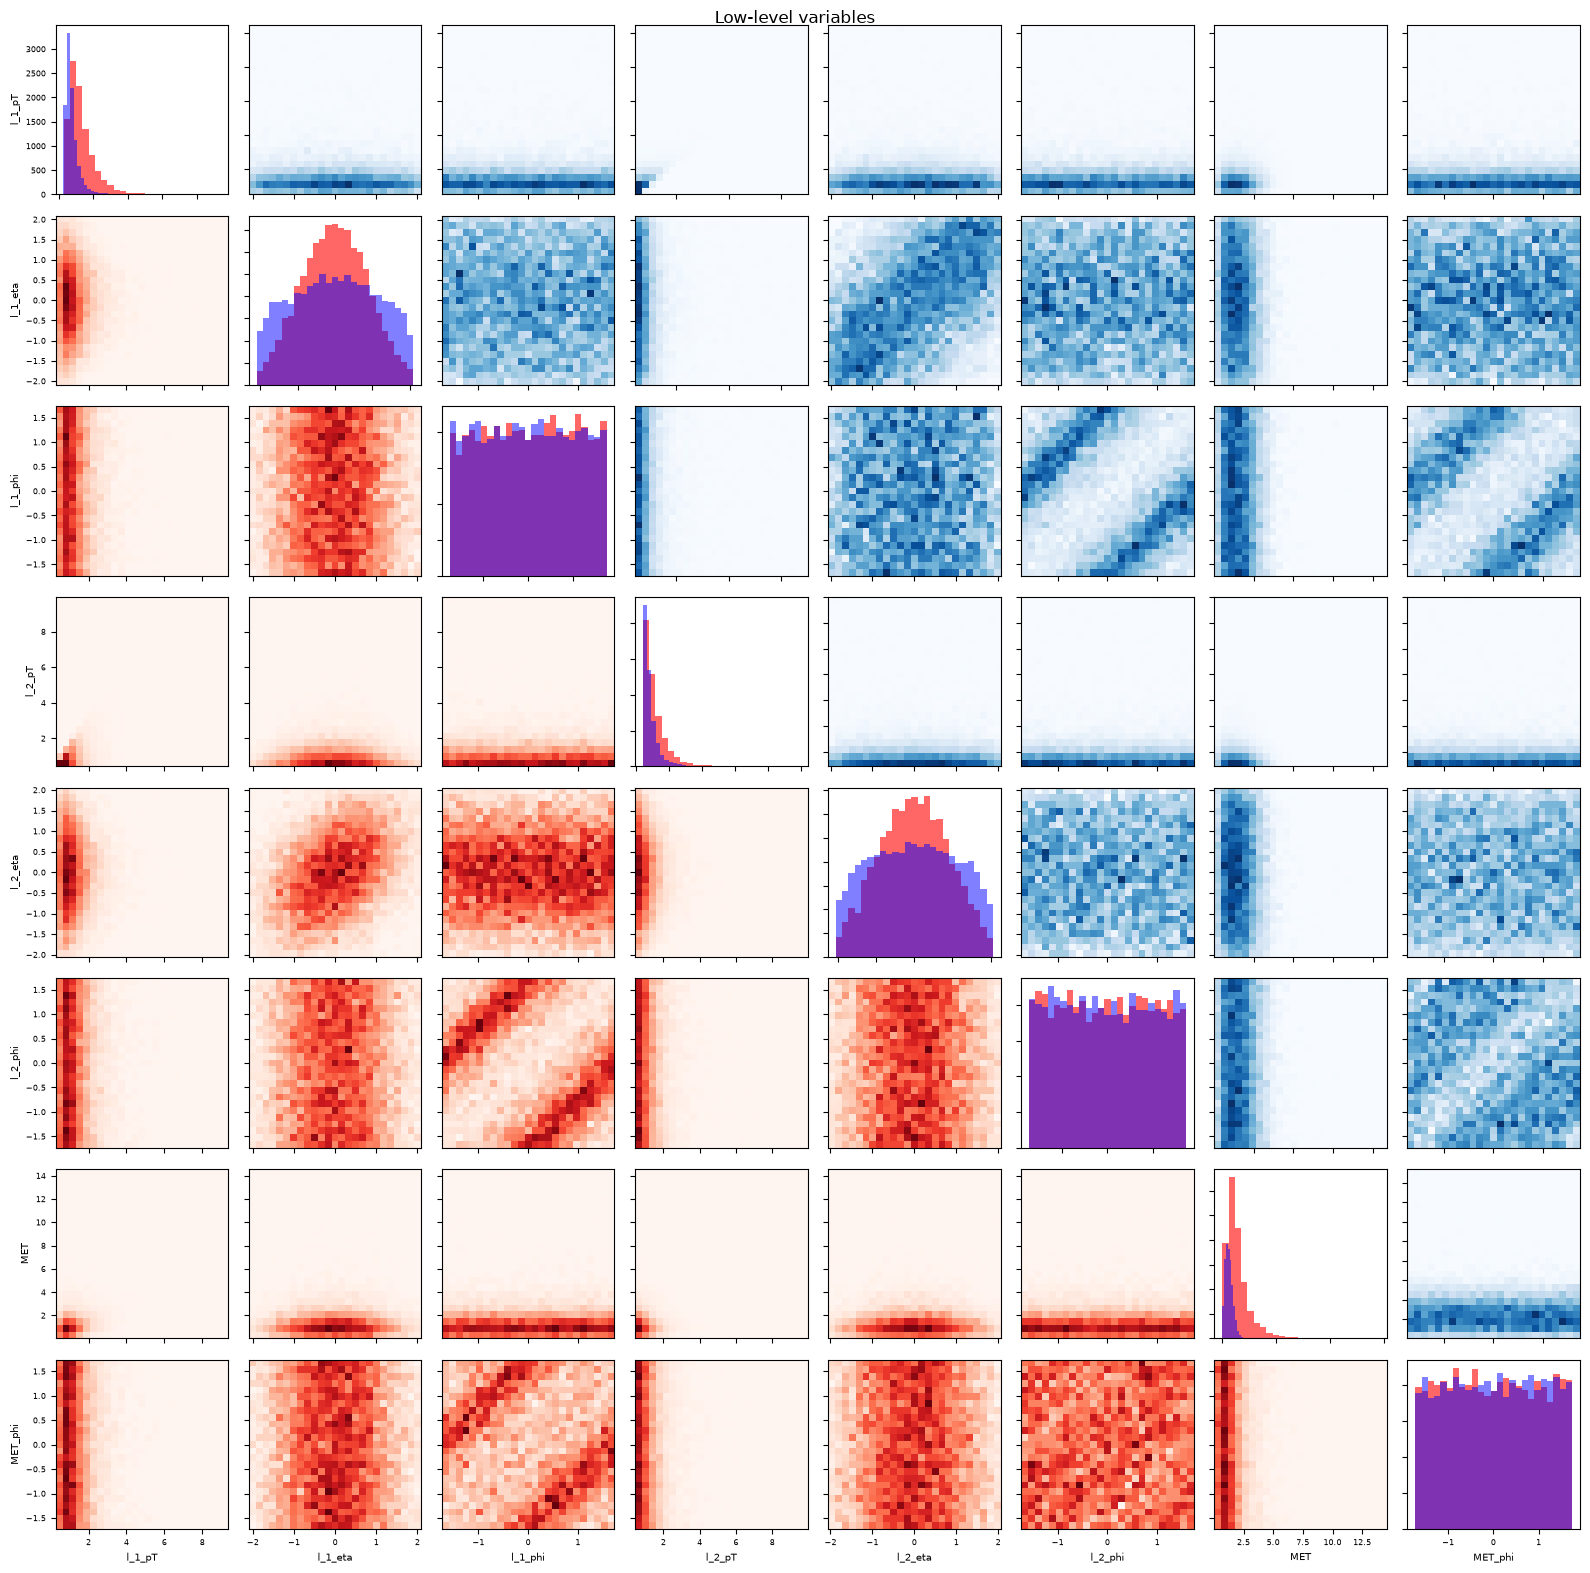

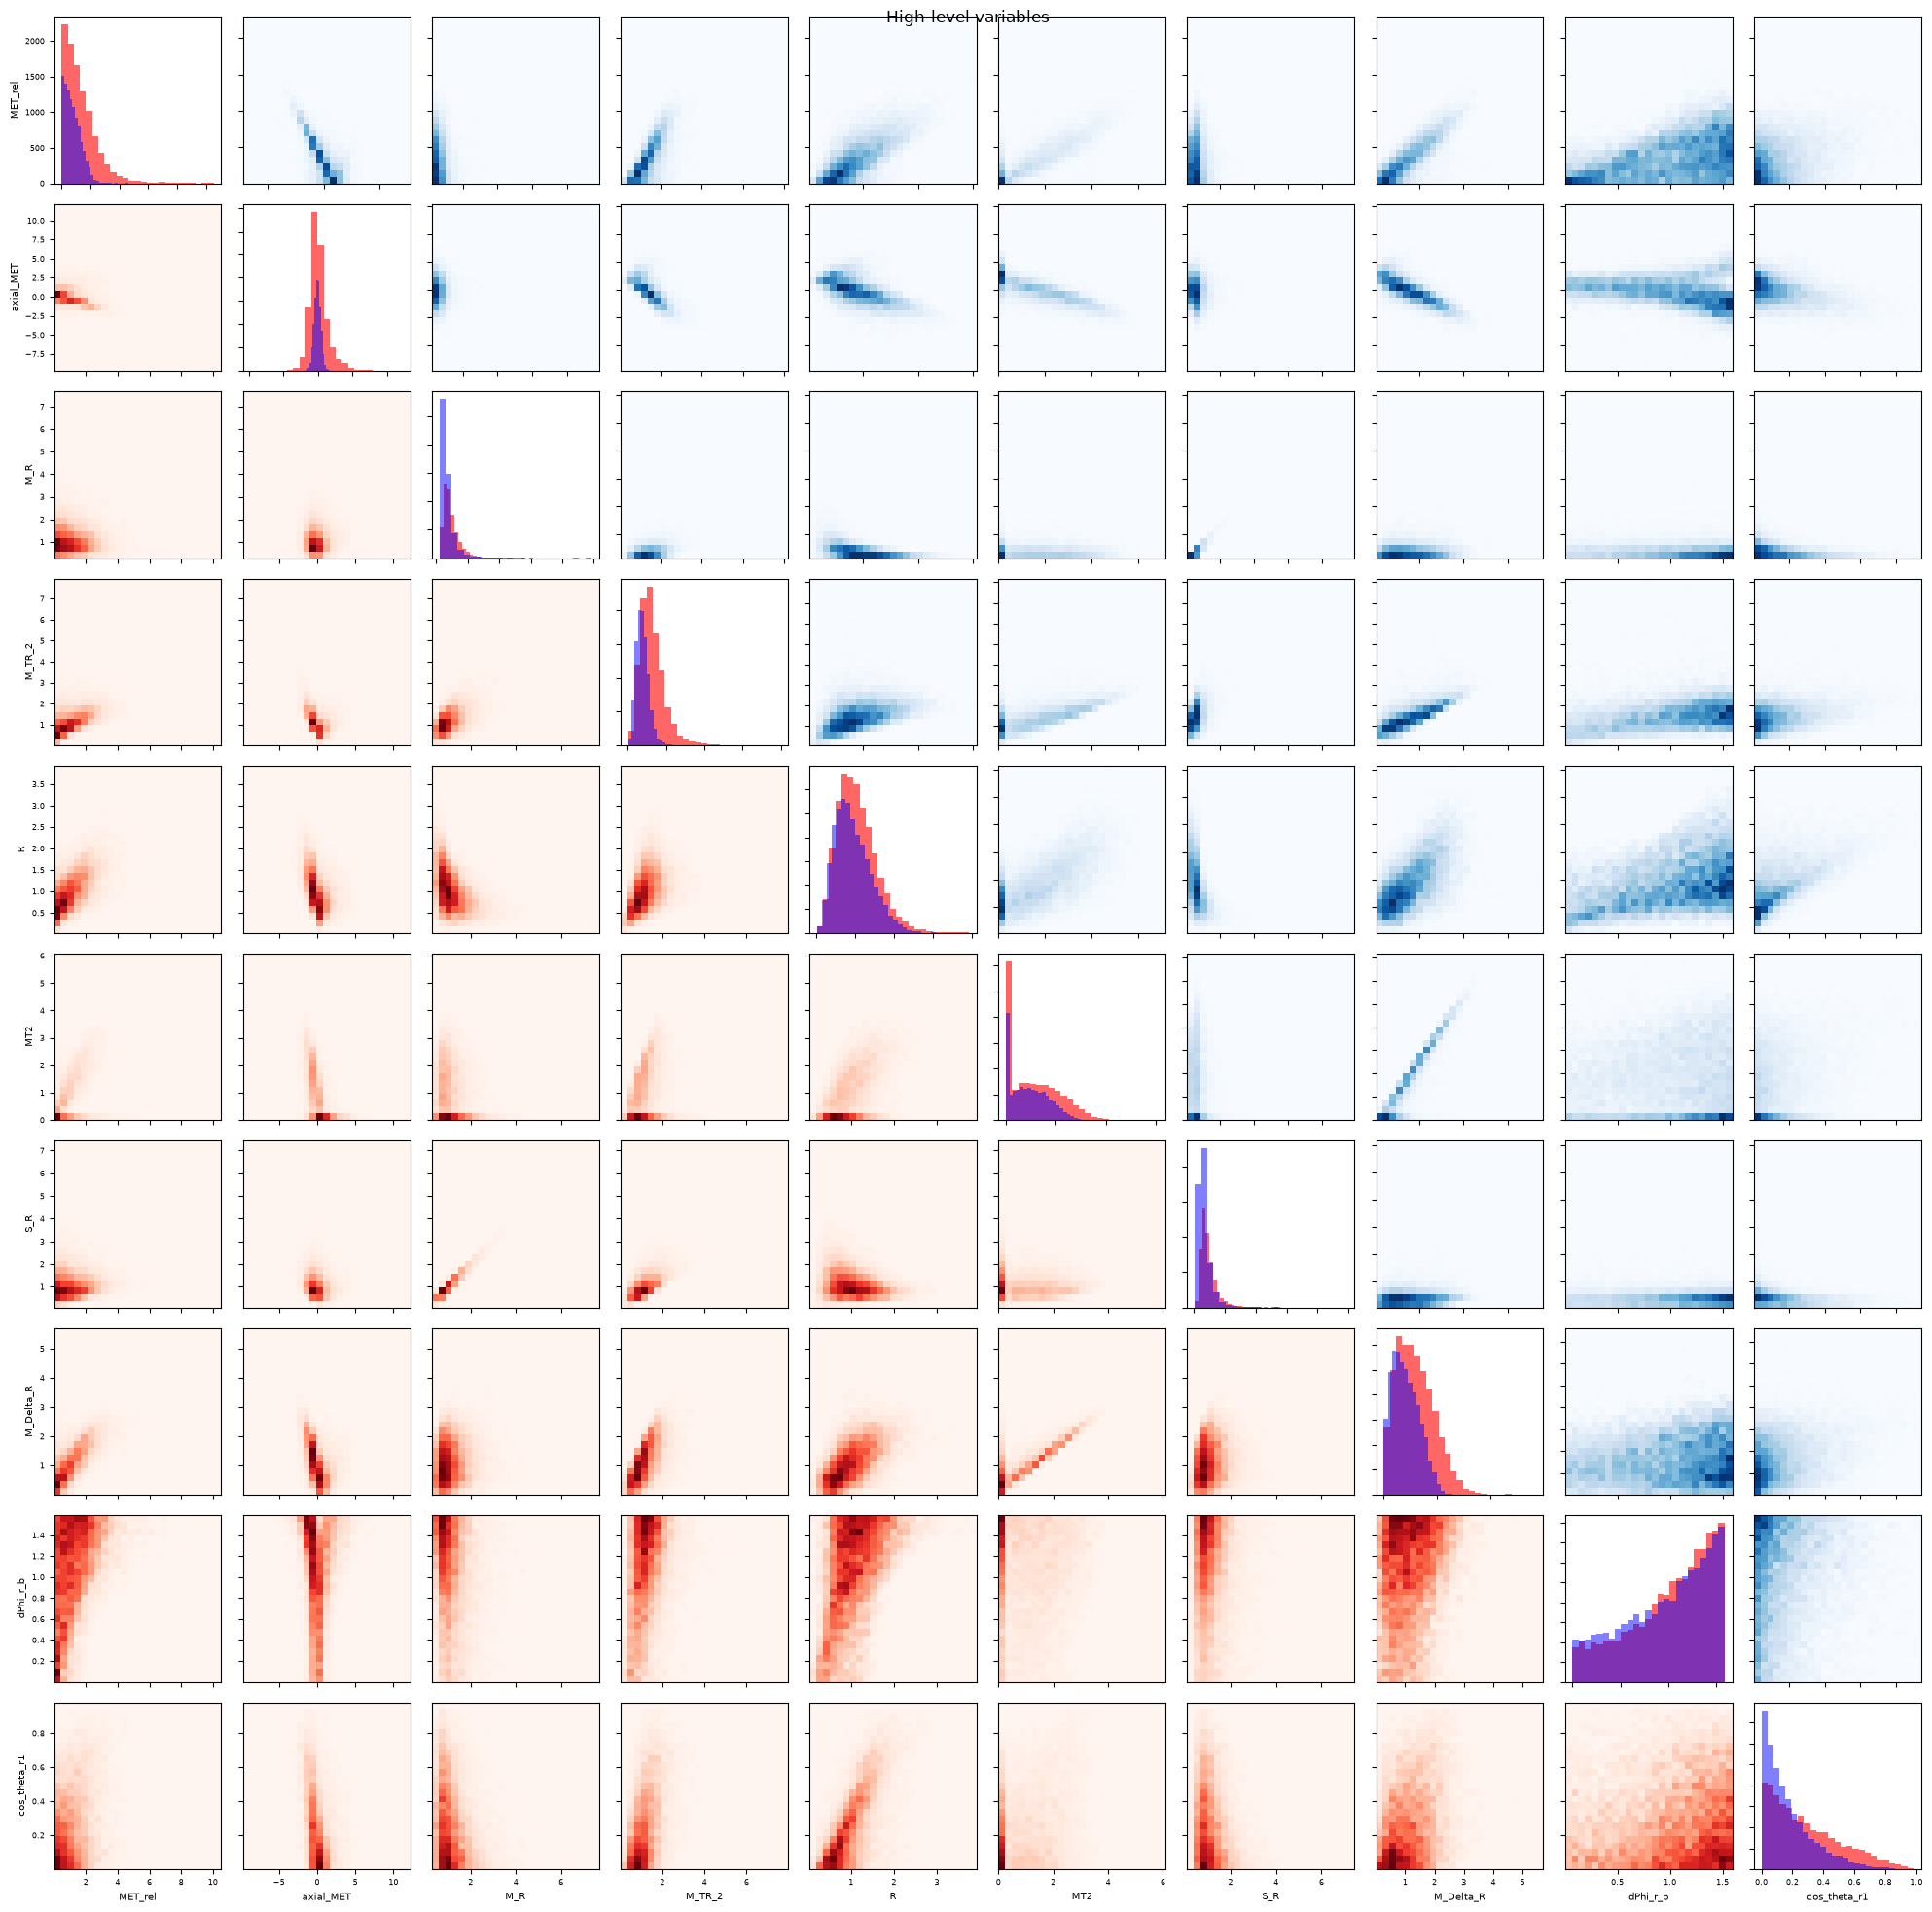

In [30]:
# part a
def pair_plot(data_signal, data_background, variables, title):
    signal_sample = data_signal.sample(n=min(10000, len(data_signal)), random_state=1)
    background_sample = data_background.sample(n=min(10000, len(data_background)), random_state=1)
    number = len(variables)
    fig, axes = plt.subplots(number, number, figsize=(2 * number, 2 * number))

    for i in range(number):
        for j in range(number):
            ax = axes[i, j]
            x_name = variables[j]
            y_name = variables[i]

            if i == j:
                ax.hist(signal_sample[x_name], bins=25, color="red", alpha=0.6)
                ax.hist(background_sample[x_name], bins=25, color="blue", alpha=0.5)
            elif i > j:
                ax.hist2d(signal_sample[x_name], signal_sample[y_name], bins=25, cmap="Reds")
            else:
                ax.hist2d(background_sample[x_name], background_sample[y_name], bins=25, cmap="Blues")

            if i == number - 1:
                ax.set_xlabel(x_name, fontsize=7)
            else:
                ax.set_xticklabels([])
            if j == 0:
                ax.set_ylabel(y_name, fontsize=7)
            else:
                ax.set_yticklabels([])
            ax.tick_params(labelsize=6)

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

pair_plot(df_sig, df_bkg, low_names, "Low-level variables")
pair_plot(df_sig, df_bkg, high_names, "High-level variables")

In [31]:
# part b + part c
separation = {}

for variable in all_names:
    signal_values = df_sig[variable].values
    background_values = df_bkg[variable].values
    low = min(np.percentile(signal_values, 1), np.percentile(background_values, 1))
    high = max(np.percentile(signal_values, 99), np.percentile(background_values, 99))
    bins = np.linspace(low, high, 51)
    signal_counts, bins = np.histogram(signal_values, bins=bins)
    background_counts, bins = np.histogram(background_values, bins=bins)
    signal_counts = signal_counts / signal_counts.sum()
    background_counts = background_counts / background_counts.sum()
    separation[variable] = 0.5 * np.sum(np.abs(signal_counts - background_counts))

ranking = sorted(all_names, key=lambda name: separation[name], reverse=True)
for variable in ranking:
    print(variable, round(separation[variable], 3))

print("Three variables with the largest histogram differences:", ranking[:3])
top_variables = ranking[:3]

MET 0.419
l_1_pT 0.406
M_TR_2 0.401
axial_MET 0.331
S_R 0.311
M_R 0.31
MET_rel 0.216
cos_theta_r1 0.21
M_Delta_R 0.198
MT2 0.194
l_2_pT 0.193
l_1_eta 0.172
l_2_eta 0.15
R 0.085
dPhi_r_b 0.031
MET_phi 0.009
l_1_phi 0.008
l_2_phi 0.007
Three variables with the largest histogram differences: ['MET', 'l_1_pT', 'M_TR_2']


### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [34]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

X,Y,Z
A,1,2
C,3,4
D,5,6


In [35]:
from IPython.display import HTML, display
from tabulate import tabulate

def show_matrices(data, variables, title):
    values = data[variables].values
    covariance = np.cov(values, rowvar=False)
    correlation = np.corrcoef(values, rowvar=False)

    covariance_rows = []
    correlation_rows = []
    for i in range(len(variables)):
        covariance_rows.append([variables[i]] + list(covariance[i]))
        correlation_rows.append([variables[i]] + list(correlation[i]))

    headers = ["Variable"] + variables
    print("Covariance matrix:", title)
    display(HTML(tabulate(covariance_rows, headers=headers, tablefmt="html", floatfmt=".3f")))
    print("Correlation matrix:", title)
    display(HTML(tabulate(correlation_rows, headers=headers, tablefmt="html", floatfmt=".2f")))
    return covariance, correlation

cov_all, corr_all = show_matrices(df, all_names, "all variables")
cov_low, corr_low = show_matrices(df, low_names, "low-level variables")
cov_high, corr_high = show_matrices(df, high_names, "high-level variables")

corr_bkg = np.corrcoef(df_bkg[all_names].values, rowvar=False)

print("Most correlated pairs within the background class:")
for i in range(len(all_names)):
    for j in range(i):
        if abs(corr_bkg[i, j]) > 0.7:
            print(all_names[i], all_names[j], round(corr_bkg[i, j], 2))

Covariance matrix: all variables


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0.000,0.000,0.305,-0.000,0.001,0.228,-0.001,0.098,-0.010,0.364,0.287,-0.060,-0.012,0.343,0.098,-0.047,0.022
l_1_eta,-0.000,1.004,-0.001,-0.000,0.408,-0.001,-0.002,-0.001,-0.001,-0.001,-0.001,-0.001,0.000,0.000,-0.001,-0.001,-0.001,0.000
l_1_phi,0.000,-0.001,1.004,0.001,0.000,-0.267,0.001,-0.185,0.001,-0.002,0.001,0.001,0.000,0.001,0.001,0.001,0.001,0.000
l_2_pT,0.305,-0.000,0.001,0.425,-0.001,0.000,0.079,-0.002,-0.001,0.051,0.325,0.163,-0.099,-0.069,0.322,0.006,-0.004,-0.028
l_2_eta,-0.000,0.408,0.000,-0.001,1.006,0.000,0.000,-0.000,0.001,-0.001,-0.001,0.000,0.000,0.001,-0.001,0.001,-0.000,0.000
l_2_phi,0.001,-0.001,-0.267,0.000,0.000,1.004,-0.000,-0.035,0.001,-0.002,0.001,0.001,0.001,0.002,0.001,0.001,-0.000,0.000
MET,0.228,-0.002,0.001,0.079,0.000,-0.000,0.762,-0.003,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.073
MET_phi,-0.001,-0.001,-0.185,-0.002,-0.000,-0.035,-0.003,1.003,-0.005,-0.000,-0.001,-0.001,-0.000,0.000,-0.002,-0.001,-0.002,0.000
MET_rel,0.098,-0.001,0.001,-0.001,0.001,0.001,0.546,-0.005,0.790,-0.120,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.010,-0.001,-0.002,0.051,-0.001,-0.002,0.154,-0.000,-0.120,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054


Correlation matrix: all variables


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1.00,-0.00,0.00,0.68,-0.00,0.00,0.38,-0.00,0.16,-0.01,0.85,0.72,-0.19,-0.02,0.81,0.23,-0.16,0.16
l_1_eta,-0.00,1.00,-0.00,-0.00,0.41,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00
l_1_phi,0.00,-0.00,1.00,0.00,0.00,-0.27,0.00,-0.18,0.00,-0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
l_2_pT,0.68,-0.00,0.00,1.00,-0.00,0.00,0.14,-0.00,-0.00,0.08,0.80,0.43,-0.32,-0.12,0.80,0.01,-0.01,-0.22
l_2_eta,-0.00,0.41,0.00,-0.00,1.00,0.00,0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00,0.00,-0.00,0.00,-0.00,0.00
l_2_phi,0.00,-0.00,-0.27,0.00,0.00,1.00,-0.00,-0.04,0.00,-0.00,0.00,0.00,0.00,0.00,0.00,0.00,-0.00,0.00
MET,0.38,-0.00,0.00,0.14,0.00,-0.00,1.00,-0.00,0.70,0.18,0.26,0.72,0.46,0.21,0.31,0.58,0.38,0.42
MET_phi,-0.00,-0.00,-0.18,-0.00,-0.00,-0.04,-0.00,1.00,-0.01,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,-0.00,0.00
MET_rel,0.16,-0.00,0.00,-0.00,0.00,0.00,0.70,-0.01,1.00,-0.13,0.08,0.58,0.59,0.54,0.15,0.75,0.38,0.32
axial_MET,-0.01,-0.00,-0.00,0.08,-0.00,-0.00,0.18,-0.00,-0.13,1.00,0.03,-0.32,-0.38,-0.54,-0.07,-0.37,-0.06,-0.27


Covariance matrix: low-level variables


...

Covariance matrix: high-level variables


Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.790,-0.120,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.120,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054
M_R,0.044,0.017,0.392,0.210,-0.113,-0.037,0.380,0.074,-0.029,-0.014
M_TR_2,0.302,-0.185,0.210,0.338,0.104,0.189,0.228,0.242,0.058,0.052
R,0.249,-0.181,-0.113,0.104,0.222,0.232,-0.083,0.165,0.087,0.058
MT2,0.409,-0.461,-0.037,0.189,0.232,0.738,-0.011,0.433,0.021,0.045
S_R,0.082,-0.041,0.380,0.228,-0.083,-0.011,0.382,0.096,-0.003,-0.010
M_Delta_R,0.415,-0.233,0.074,0.242,0.165,0.433,0.096,0.389,0.042,0.039
dPhi_r_b,0.146,-0.025,-0.029,0.058,0.087,0.021,-0.003,0.042,0.190,0.009
cos_theta_r1,0.055,-0.054,-0.014,0.052,0.058,0.045,-0.010,0.039,0.009,0.039


Correlation matrix: high-level variables


Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,1.00,-0.13,0.08,0.58,0.59,0.54,0.15,0.75,0.38,0.32
axial_MET,-0.13,1.00,0.03,-0.32,-0.38,-0.54,-0.07,-0.37,-0.06,-0.27
M_R,0.08,0.03,1.00,0.58,-0.38,-0.07,0.98,0.19,-0.11,-0.12
M_TR_2,0.58,-0.32,0.58,1.00,0.38,0.38,0.64,0.67,0.23,0.45
R,0.59,-0.38,-0.38,0.38,1.00,0.57,-0.29,0.56,0.42,0.63
MT2,0.54,-0.54,-0.07,0.38,0.57,1.00,-0.02,0.81,0.06,0.26
S_R,0.15,-0.07,0.98,0.64,-0.29,-0.02,1.00,0.25,-0.01,-0.09
M_Delta_R,0.75,-0.37,0.19,0.67,0.56,0.81,0.25,1.00,0.16,0.32
dPhi_r_b,0.38,-0.06,-0.11,0.23,0.42,0.06,-0.01,0.16,1.00,0.11
cos_theta_r1,0.32,-0.27,-0.12,0.45,0.63,0.26,-0.09,0.32,0.11,1.00


Most correlated pairs within the background class:
l_2_pT l_1_pT 0.82
MET_rel MET 0.83
M_R l_1_pT 0.82
M_R l_2_pT 0.79
M_TR_2 MET 0.83
MT2 MET_rel 0.77
MT2 axial_MET -0.76
S_R l_1_pT 0.81
S_R l_2_pT 0.79
S_R M_R 0.99
M_Delta_R MET 0.73
M_Delta_R MET_rel 0.81
M_Delta_R axial_MET -0.79
M_Delta_R M_TR_2 0.73
M_Delta_R MT2 0.93


## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

In [36]:
# 5.1
SCENARIOS = [(10, 100), (100, 1000), (1000, 10000), (10000, 100000)]
REF = (1000, 10000)
KIND = {1: "x > xc", 2: "x < xc", 3: "abs(x - mean) > xc", 4: "abs(x - mean) < xc"}
means = df[all_names].mean()

def significance(eff_signal, eff_background, n_signal, n_background):
    signal_after = eff_signal * n_signal
    background_after = eff_background * n_background
    total = signal_after + background_after
    if np.ndim(total) == 0:
        if total == 0:
            return 0
        return signal_after / np.sqrt(total)
    result = np.zeros_like(total, dtype=float)
    valid = total > 0
    result[valid] = signal_after[valid] / np.sqrt(total[valid])
    return result

def changed_values(values, variable, kind):
    if kind == 3 or kind == 4:
        return np.abs(values - means[variable])
    return values

def get_efficiencies(signal_values, background_values, variable, kind, cuts):
    signal_values = changed_values(signal_values, variable, kind)
    background_values = changed_values(background_values, variable, kind)
    signal_sorted = np.sort(signal_values)
    background_sorted = np.sort(background_values)

    if kind == 1 or kind == 3:
        signal_eff = (len(signal_sorted) - np.searchsorted(signal_sorted, cuts, side="right")) / len(signal_sorted)
        background_eff = (len(background_sorted) - np.searchsorted(background_sorted, cuts, side="right")) / len(background_sorted)
    else:
        signal_eff = np.searchsorted(signal_sorted, cuts, side="left") / len(signal_sorted)
        background_eff = np.searchsorted(background_sorted, cuts, side="left") / len(background_sorted)
    return signal_eff, background_eff

def make_cut_values(signal_values, background_values, variable, kind, number=100):
    signal_values = changed_values(signal_values, variable, kind)
    background_values = changed_values(background_values, variable, kind)
    both = np.concatenate([signal_values, background_values])
    low = np.percentile(both, 1)
    high = np.percentile(both, 99)
    return np.linspace(low, high, number)

best = {}
best_curves = {}

for variable in all_names:
    signal_values = df_sig[variable].values
    background_values = df_bkg[variable].values
    best_significance = -1

    for kind in [1, 2, 3, 4]:
        cuts = make_cut_values(signal_values, background_values, variable, kind)
        signal_eff, background_eff = get_efficiencies(signal_values, background_values, variable, kind, cuts)
        values = significance(signal_eff, background_eff, REF[0], REF[1])
        best_index = np.argmax(values)

        if values[best_index] > best_significance:
            best_significance = values[best_index]
            best[variable] = {
                "kind": kind,
                "cut": cuts[best_index],
                "signal_eff": signal_eff[best_index],
                "background_eff": background_eff[best_index],
                "significance": values[best_index]
            }
            best_curves[variable] = (cuts, signal_eff, background_eff)

rank_sig = sorted(all_names, key=lambda name: best[name]["significance"], reverse=True)

print("Best cut for each variable:")
for variable in rank_sig:
    result = best[variable]
    print(variable, KIND[result["kind"]], round(result["cut"], 3),
          "significance:", round(result["significance"], 3))

Best cut for each variable:
MET x > xc 1.559 significance: 14.983
axial_MET abs(x - mean) > xc 1.255 significance: 13.184
M_TR_2 x > xc 1.316 significance: 12.713
l_1_pT x > xc 0.949 significance: 11.762
M_R x > xc 0.67 significance: 10.488
S_R x > xc 0.701 significance: 10.471
l_1_eta abs(x - mean) < xc 1.503 significance: 9.761
MET_rel abs(x - mean) > xc 1.278 significance: 9.718
l_2_eta abs(x - mean) < xc 1.636 significance: 9.622
M_Delta_R x > xc 0.062 significance: 9.536
cos_theta_r1 x > xc 0.003 significance: 9.533
l_2_pT x > xc 0.435 significance: 9.517
MT2 abs(x - mean) > xc 0.014 significance: 9.513
R x > xc 0.208 significance: 9.511
dPhi_r_b x > xc 0.032 significance: 9.495
l_2_phi abs(x - mean) > xc 0.017 significance: 9.487
l_1_phi x > xc -1.701 significance: 9.487
MET_phi x > xc -1.692 significance: 9.486


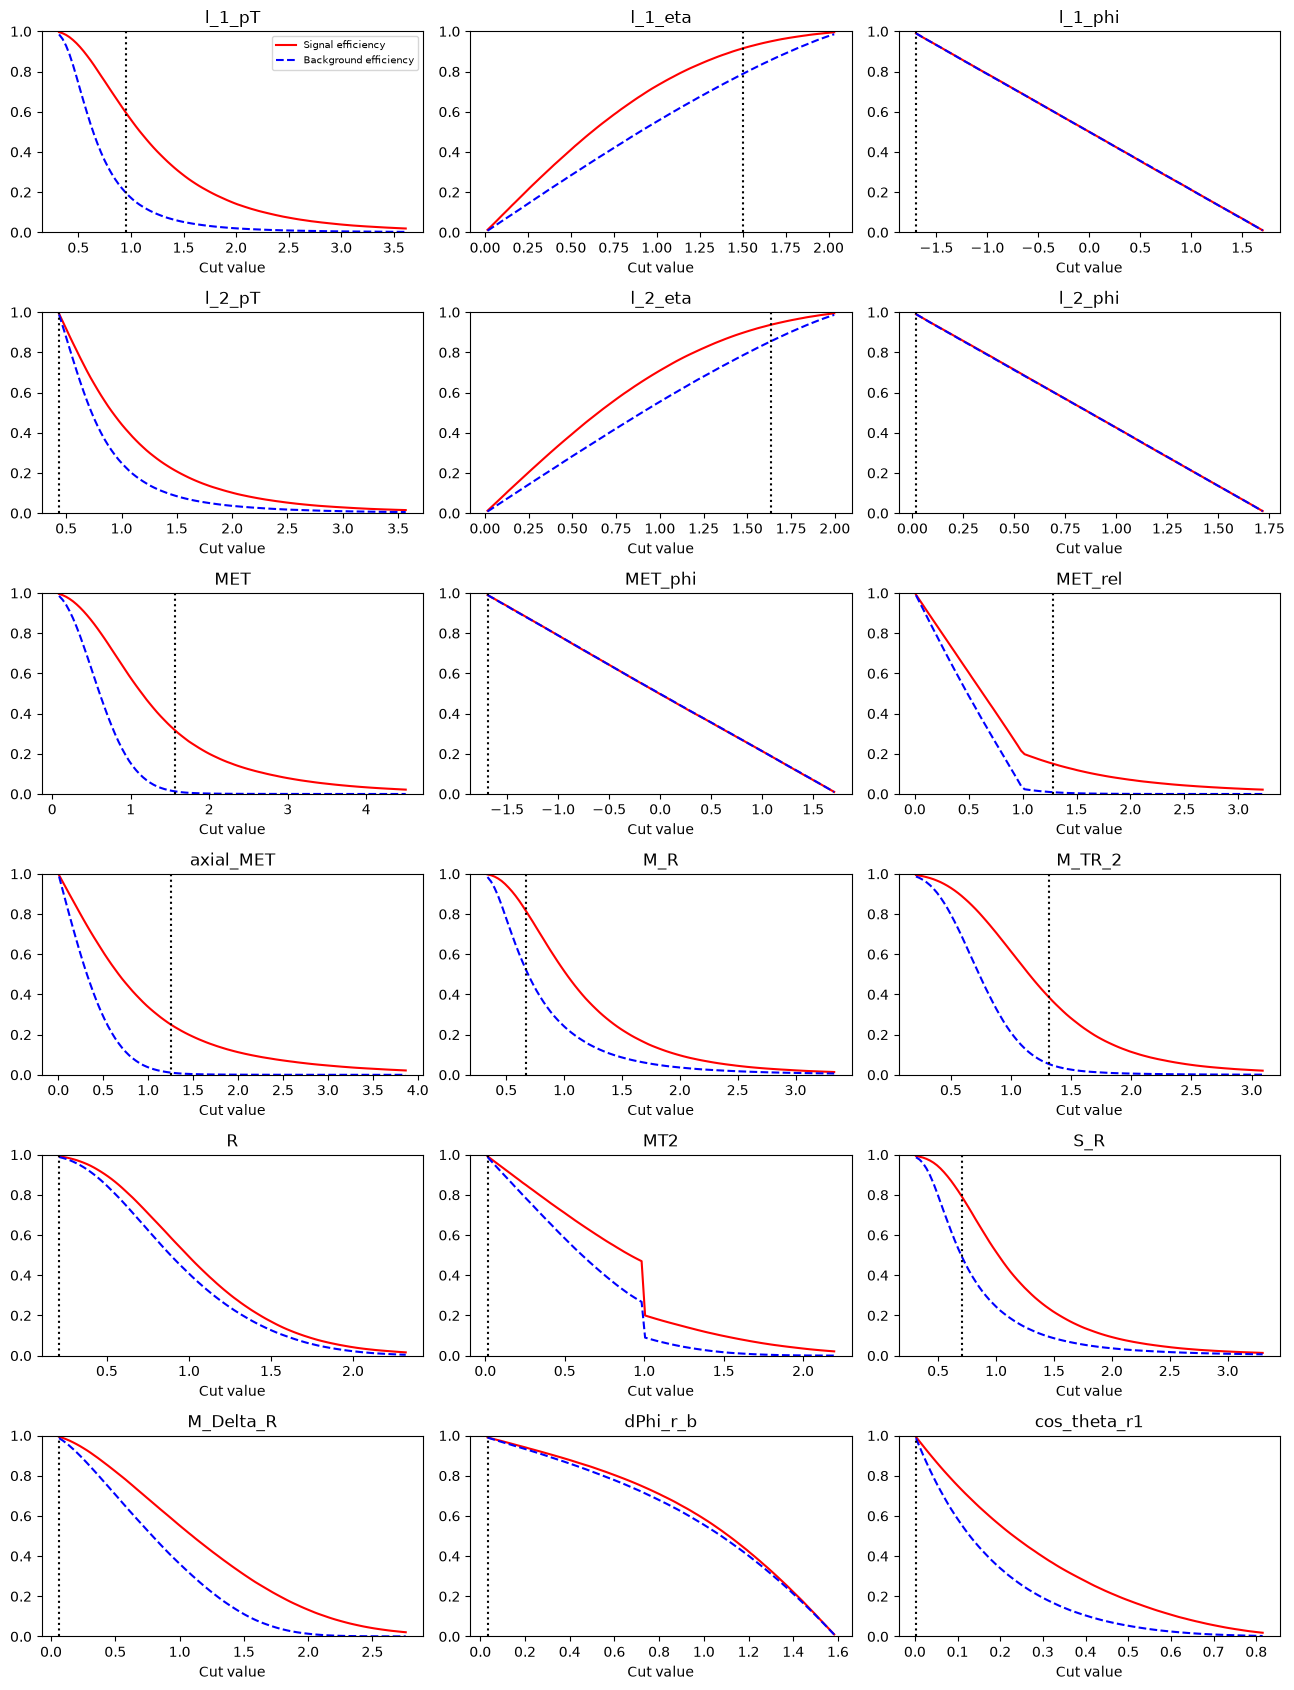

In [37]:
# 5.2
fig, axes = plt.subplots(6, 3, figsize=(13, 17))

for ax, variable in zip(axes.flat, all_names):
    cuts, signal_eff, background_eff = best_curves[variable]
    ax.plot(cuts, signal_eff, color="red", label="Signal efficiency")
    ax.plot(cuts, background_eff, color="blue", linestyle="--", label="Background efficiency")
    ax.axvline(best[variable]["cut"], color="black", linestyle=":")
    ax.set_title(variable)
    ax.set_xlabel("Cut value")
    ax.set_ylim(0, 1)

for ax in axes.flat[len(all_names):]:
    ax.axis("off")
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
plt.show()

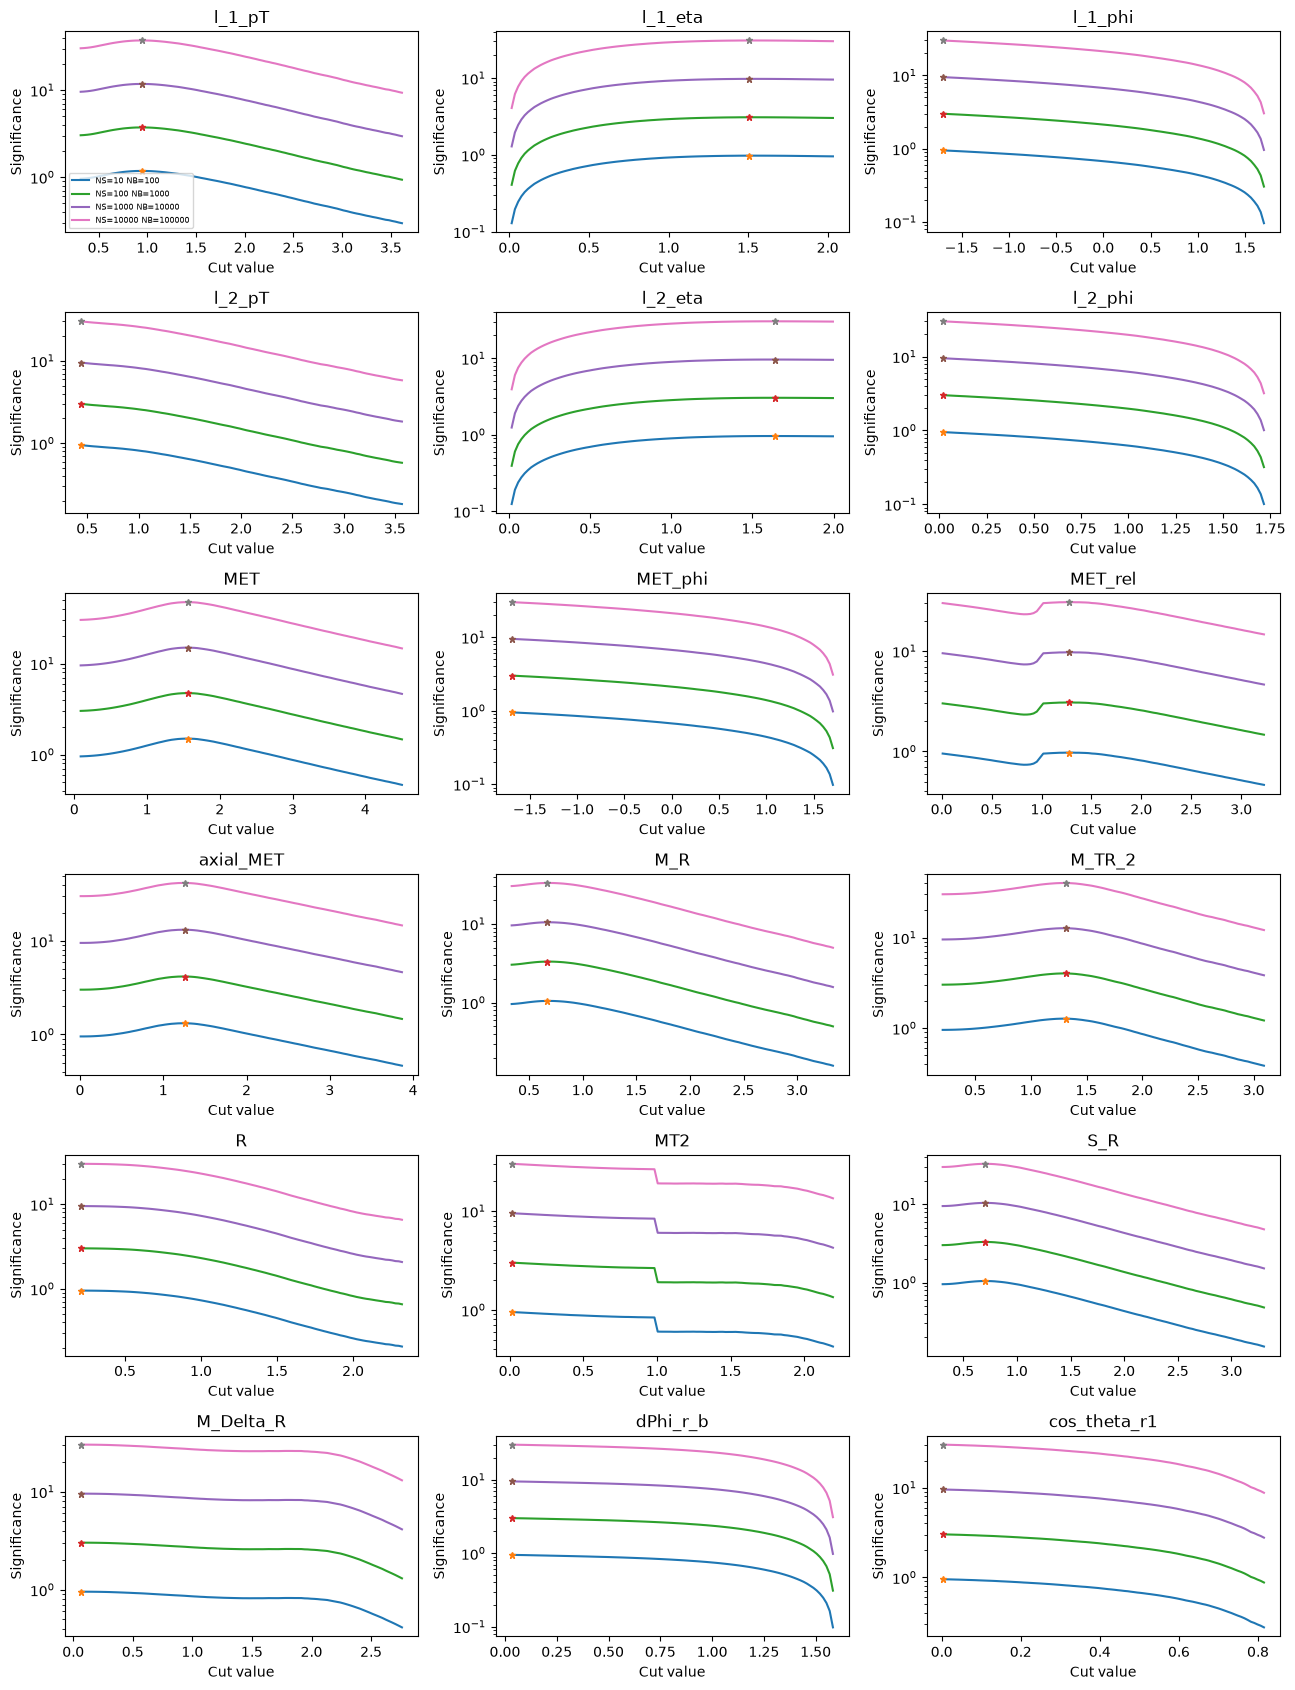

Top variables by best single-cut significance:
MET 14.983 cut: 1.559 x > xc
axial_MET 13.184 cut: 1.255 abs(x - mean) > xc
M_TR_2 12.713 cut: 1.316 x > xc
l_1_pT 11.762 cut: 0.949 x > xc
M_R 10.488 cut: 0.67 x > xc
S_R 10.471 cut: 0.701 x > xc


In [38]:
# 5.3
fig, axes = plt.subplots(6, 3, figsize=(13, 17))

for ax, variable in zip(axes.flat, all_names):
    cuts, signal_eff, background_eff = best_curves[variable]
    for n_signal, n_background in SCENARIOS:
        values = significance(signal_eff, background_eff, n_signal, n_background)
        ax.plot(cuts, values, label="NS={} NB={}".format(n_signal, n_background))
        best_index = np.argmax(values)
        ax.plot(cuts[best_index], values[best_index], "*", markersize=5)
    ax.set_title(variable)
    ax.set_xlabel("Cut value")
    ax.set_ylabel("Significance")
    ax.set_yscale("log")

for ax in axes.flat[len(all_names):]:
    ax.axis("off")
axes[0, 0].legend(fontsize=6)
fig.tight_layout()
plt.show()

print("Top variables by best single-cut significance:")
for variable in rank_sig[:6]:
    print(variable, round(best[variable]["significance"], 3),
          "cut:", round(best[variable]["cut"], 3), KIND[best[variable]["kind"]])

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




In [39]:
# 6.1 + 6.2
selections = []
for variable in rank_sig[:3]:
    selections.append((variable, best[variable]["kind"], best[variable]["cut"]))

print("Cuts used:")
for variable, kind, cut in selections:
    print(variable, KIND[kind], round(cut, 3))

def cut_mask(values, variable, kind, cut):
    if kind == 1:
        return values > cut
    if kind == 2:
        return values < cut
    if kind == 3:
        return np.abs(values - means[variable]) > cut
    return np.abs(values - means[variable]) < cut

def cutflow(selected_cuts, n_signal, n_background):
    signal_mask = np.ones(len(df_sig), dtype=bool)
    background_mask = np.ones(len(df_bkg), dtype=bool)
    rows = []

    signal_eff = 1.0
    background_eff = 1.0
    rows.append(["No cuts", signal_eff, background_eff, n_signal, n_background,
                 significance(signal_eff, background_eff, n_signal, n_background)])

    for variable, kind, cut in selected_cuts:
        signal_mask = signal_mask & cut_mask(df_sig[variable].values, variable, kind, cut)
        background_mask = background_mask & cut_mask(df_bkg[variable].values, variable, kind, cut)
        signal_eff = np.mean(signal_mask)
        background_eff = np.mean(background_mask)
        rows.append([variable, signal_eff, background_eff,
                     signal_eff * n_signal, background_eff * n_background,
                     significance(signal_eff, background_eff, n_signal, n_background)])
    return rows

headers = ["Selection", "Signal efficiency", "Background efficiency", "Signal left", "Background left", "Significance"]
for n_signal, n_background in SCENARIOS:
    print("Cut flow for NS={}, NB={}".format(n_signal, n_background))
    display(HTML(tabulate(cutflow(selections, n_signal, n_background),
                          headers=headers, tablefmt="html", floatfmt=".3f")))

Cuts used:
MET x > xc 1.559
axial_MET abs(x - mean) > xc 1.255
M_TR_2 x > xc 1.316
Cut flow for NS=10, NB=100


Selection,Signal efficiency,Background efficiency,Signal left,Background left,Significance
No cuts,1.000,1.000,10.000,100.000,0.953
MET,0.319,0.013,3.187,1.337,1.498
axial_MET,0.219,0.008,2.193,0.792,1.269
M_TR_2,0.154,0.007,1.545,0.673,1.037


Cut flow for NS=100, NB=1000


Selection,Signal efficiency,Background efficiency,Signal left,Background left,Significance
No cuts,1.000,1.000,100.000,1000.000,3.015
MET,0.319,0.013,31.865,13.366,4.738
axial_MET,0.219,0.008,21.935,7.922,4.014
M_TR_2,0.154,0.007,15.447,6.726,3.280


Cut flow for NS=1000, NB=10000


Selection,Signal efficiency,Background efficiency,Signal left,Background left,Significance
No cuts,1.000,1.000,1000.000,10000.000,9.535
MET,0.319,0.013,318.655,133.663,14.983
axial_MET,0.219,0.008,219.346,79.223,12.694
M_TR_2,0.154,0.007,154.468,67.256,10.374


Cut flow for NS=10000, NB=100000


Selection,Signal efficiency,Background efficiency,Signal left,Background left,Significance
No cuts,1.000,1.000,10000.000,100000.000,30.151
MET,0.319,0.013,3186.547,1336.633,47.380
axial_MET,0.219,0.008,2193.461,792.229,40.143
M_TR_2,0.154,0.007,1544.679,672.564,32.804


In [40]:
# 6.3
selections = []
for variable in rank_sig[:3]:
    selections.append((variable, best[variable]["kind"], best[variable]["cut"]))

print("Cuts used:")
for variable, kind, cut in selections:
    print(variable, KIND[kind], round(cut, 3))

def cut_mask(values, variable, kind, cut):
    if kind == 1:
        return values > cut
    if kind == 2:
        return values < cut
    if kind == 3:
        return np.abs(values - means[variable]) > cut
    return np.abs(values - means[variable]) < cut

def cutflow(selected_cuts, n_signal, n_background):
    signal_mask = np.ones(len(df_sig), dtype=bool)
    background_mask = np.ones(len(df_bkg), dtype=bool)
    rows = []

    signal_eff = 1.0
    background_eff = 1.0
    rows.append(["No cuts", signal_eff, background_eff, n_signal, n_background,
                 significance(signal_eff, background_eff, n_signal, n_background)])

    for variable, kind, cut in selected_cuts:
        signal_mask = signal_mask & cut_mask(df_sig[variable].values, variable, kind, cut)
        background_mask = background_mask & cut_mask(df_bkg[variable].values, variable, kind, cut)
        signal_eff = np.mean(signal_mask)
        background_eff = np.mean(background_mask)
        rows.append([variable, signal_eff, background_eff,
                     signal_eff * n_signal, background_eff * n_background,
                     significance(signal_eff, background_eff, n_signal, n_background)])
    return rows

headers = ["Selection", "Signal efficiency", "Background efficiency", "Signal left", "Background left", "Significance"]
for n_signal, n_background in SCENARIOS:
    print("Cut flow for NS={}, NB={}".format(n_signal, n_background))
    display(HTML(tabulate(cutflow(selections, n_signal, n_background),
                          headers=headers, tablefmt="html", floatfmt=".3f")))

Cuts used:
MET x > xc 1.559
axial_MET abs(x - mean) > xc 1.255
M_TR_2 x > xc 1.316
Cut flow for NS=10, NB=100


Selection,Signal efficiency,Background efficiency,Signal left,Background left,Significance
No cuts,1.000,1.000,10.000,100.000,0.953
MET,0.319,0.013,3.187,1.337,1.498
axial_MET,0.219,0.008,2.193,0.792,1.269
M_TR_2,0.154,0.007,1.545,0.673,1.037


Cut flow for NS=100, NB=1000


Selection,Signal efficiency,Background efficiency,Signal left,Background left,Significance
No cuts,1.000,1.000,100.000,1000.000,3.015
MET,0.319,0.013,31.865,13.366,4.738
axial_MET,0.219,0.008,21.935,7.922,4.014
M_TR_2,0.154,0.007,15.447,6.726,3.280


Cut flow for NS=1000, NB=10000


Selection,Signal efficiency,Background efficiency,Signal left,Background left,Significance
No cuts,1.000,1.000,1000.000,10000.000,9.535
MET,0.319,0.013,318.655,133.663,14.983
axial_MET,0.219,0.008,219.346,79.223,12.694
M_TR_2,0.154,0.007,154.468,67.256,10.374


Cut flow for NS=10000, NB=100000


Selection,Signal efficiency,Background efficiency,Signal left,Background left,Significance
No cuts,1.000,1.000,10000.000,100000.000,30.151
MET,0.319,0.013,3186.547,1336.633,47.380
axial_MET,0.219,0.008,2193.461,792.229,40.143
M_TR_2,0.154,0.007,1544.679,672.564,32.804


## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



In [46]:
def plot_roc_for_variables(variables, title, signal_mask=None, background_mask=None):
    if signal_mask is None:
        signal_mask = np.ones(len(df_sig), dtype=bool)

    if background_mask is None:
        background_mask = np.ones(len(df_bkg), dtype=bool)

    plt.figure(figsize=(7, 5))

    for variable in variables:
        kind = best[variable]["kind"]

        signal_scores = make_score(
            df_sig[variable].values[signal_mask], variable, kind
        )

        background_scores = make_score(
            df_bkg[variable].values[background_mask], variable, kind
        )

        fpr, tpr = make_roc(signal_scores, background_scores)
        area = np.trapezoid(tpr, fpr)

        plt.plot(
            fpr, tpr,
            label="{} (AUC = {:.3f})".format(variable, area)
        )

    plt.plot([0, 1], [0, 1], "k:")
    plt.xlabel("Background efficiency")
    plt.ylabel("Signal efficiency")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

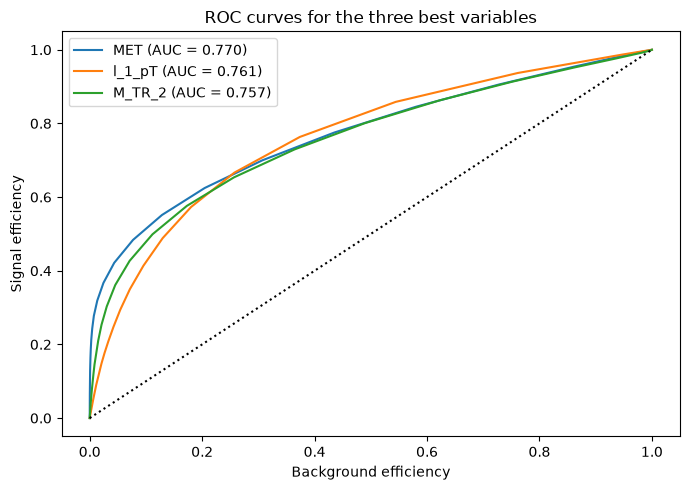

In [47]:
# 7.1
plot_roc_for_variables(top_variables, "ROC curves for the three best variables")

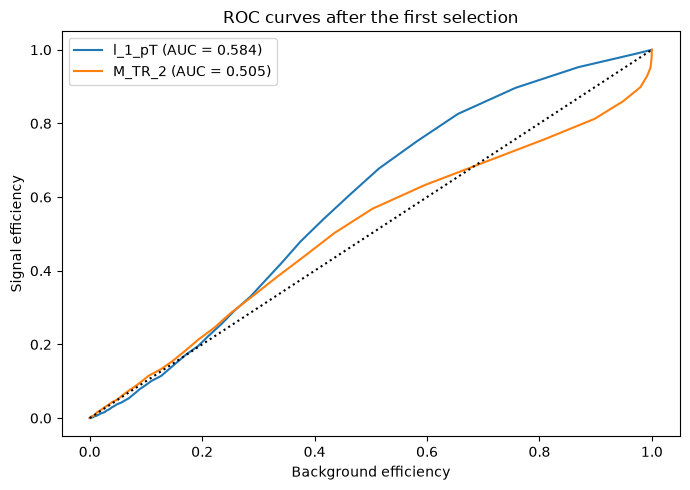

In [49]:
# 7.2
first_variable, first_kind, first_cut = selections[0]

signal_mask = cut_mask(
    df_sig[first_variable].values,
    first_variable, first_kind, first_cut
)

background_mask = cut_mask(
    df_bkg[first_variable].values,
    first_variable, first_kind, first_cut
)

other_variables = [
    variable for variable in top_variables
    if variable != first_variable
]

plot_roc_for_variables(
    other_variables,
    "ROC curves after the first selection",
    signal_mask,
    background_mask
)

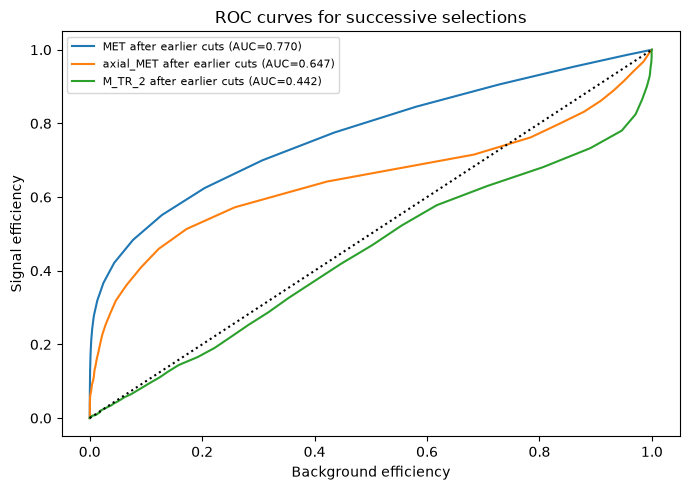

In [52]:
# 7.3
signal_mask = np.ones(len(df_sig), dtype=bool)
background_mask = np.ones(len(df_bkg), dtype=bool)
plt.figure(figsize=(7, 5))

for variable, kind, cut in selections:
    signal_scores = make_score(df_sig[variable].values[signal_mask], variable, kind)
    background_scores = make_score(df_bkg[variable].values[background_mask], variable, kind)
    fpr, tpr = make_roc(signal_scores, background_scores)
    area = np.trapezoid(tpr, fpr)
    plt.plot(fpr, tpr, label="{} after earlier cuts (AUC={:.3f})".format(variable, area))

    signal_mask = signal_mask & cut_mask(df_sig[variable].values, variable, kind, cut)
    background_mask = background_mask & cut_mask(df_bkg[variable].values, variable, kind, cut)

plt.plot([0, 1], [0, 1], "k:")
plt.xlabel("Background efficiency")
plt.ylabel("Signal efficiency")
plt.title("ROC curves for successive selections")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

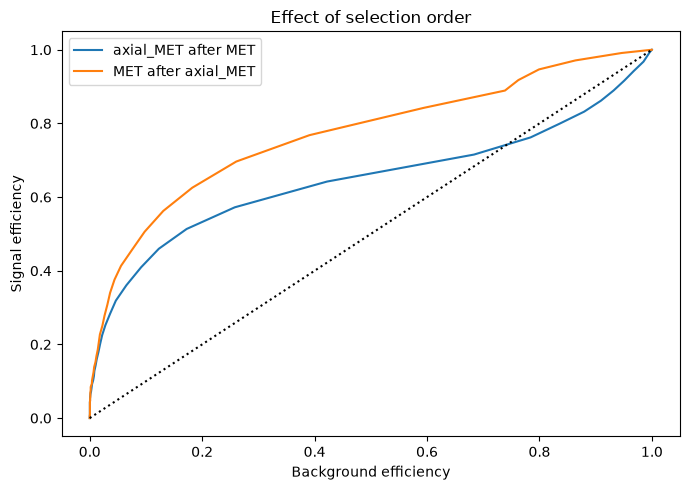

Signal efficiency after both cuts, A then B: 0.2193461144190713
Signal efficiency after both cuts, B then A: 0.2193461144190713
Background efficiency after both cuts, A then B: 0.007922291370427138
Background efficiency after both cuts, B then A: 0.007922291370427138


In [54]:
# 7.4
varA, kindA, valueA = selections[0]
varB, kindB, valueB = selections[1]

cutA = (varA, kindA, valueA)
cutB = (varB, kindB, valueB)
maskA_signal = cut_mask(df_sig[varA].values, varA, cutA[1], cutA[2])
maskA_background = cut_mask(df_bkg[varA].values, varA, cutA[1], cutA[2])
maskB_signal = cut_mask(df_sig[varB].values, varB, cutB[1], cutB[2])
maskB_background = cut_mask(df_bkg[varB].values, varB, cutB[1], cutB[2])

plt.figure(figsize=(7, 5))

scores_signal = make_score(df_sig[varB].values[maskA_signal], varB, best[varB]["kind"])
scores_background = make_score(df_bkg[varB].values[maskA_background], varB, best[varB]["kind"])
fpr, tpr = make_roc(scores_signal, scores_background)
plt.plot(fpr, tpr, label=varB + " after " + varA)

scores_signal = make_score(df_sig[varA].values[maskB_signal], varA, best[varA]["kind"])
scores_background = make_score(df_bkg[varA].values[maskB_background], varA, best[varA]["kind"])
fpr, tpr = make_roc(scores_signal, scores_background)
plt.plot(fpr, tpr, label=varA + " after " + varB)

plt.plot([0, 1], [0, 1], "k:")
plt.xlabel("Background efficiency")
plt.ylabel("Signal efficiency")
plt.title("Effect of selection order")
plt.legend()
plt.tight_layout()
plt.show()

print("Signal efficiency after both cuts, A then B:", np.mean(maskA_signal & maskB_signal))
print("Signal efficiency after both cuts, B then A:", np.mean(maskB_signal & maskA_signal))
print("Background efficiency after both cuts, A then B:", np.mean(maskA_background & maskB_background))
print("Background efficiency after both cuts, B then A:", np.mean(maskB_background & maskA_background))

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

In [56]:
# 8.1
signal_data = df_sig[all_names].values
background_data = df_bkg[all_names].values

mean_signal = np.mean(signal_data, axis=0)
mean_background = np.mean(background_data, axis=0)

mean_difference = mean_background - mean_signal

S_B = np.outer(mean_difference, mean_difference)

signal_centered = signal_data - mean_signal
background_centered = background_data - mean_background

S_W = (
    signal_centered.T @ signal_centered
    + background_centered.T @ background_centered
)

print("Between-class matrix S_B:")
print(S_B)

print("Within-class matrix S_W:")
print(S_W)

Between-class matrix S_B:
[[ 2.87970231e-01  4.58922304e-04  4.67467434e-04  1.38148662e-01
   1.54068049e-03  3.66095560e-04  4.13461344e-01 -6.36618070e-04
   2.71136238e-01  8.54657090e-02  1.82331687e-01  2.66557653e-01
   5.53227373e-02  7.37824064e-02  1.74241790e-01  1.84116478e-01
   1.54056891e-02  5.66281031e-02]
 [ 4.58922304e-04  7.31359210e-07  7.44977113e-07  2.20159917e-04
   2.45529768e-06  5.83426339e-07  6.58910580e-04 -1.01454317e-06
   4.32094896e-04  1.36201995e-04  2.90571971e-04  4.24798257e-04
   8.81648006e-05  1.17582959e-04  2.77679548e-04  2.93416294e-04
   2.45511986e-05  9.02450903e-05]
 [ 4.67467434e-04  7.44977113e-07  7.58848582e-07  2.24259293e-04
   2.50101531e-06  5.94289733e-07  6.71179491e-04 -1.03343396e-06
   4.40140500e-04  1.38738075e-04  2.95982420e-04  4.32707998e-04
   8.98064286e-05  1.19772353e-04  2.82849940e-04  2.98879704e-04
   2.50083417e-05  9.19254533e-05]
 [ 1.38148662e-01  2.20159917e-04  2.24259293e-04  6.62743950e-02
   7.391144

Fisher coefficients:
l_1_pT -2e-06
l_1_eta -0.0
l_1_phi -0.0
l_2_pT -1e-06
l_2_eta -0.0
l_2_phi -0.0
MET -2e-06
MET_phi -0.0
MET_rel -0.0
axial_MET -0.0
M_R 0.0
M_TR_2 -0.0
R 2e-06
MT2 0.0
S_R 2e-06
M_Delta_R -2e-06
dPhi_r_b 0.0
cos_theta_r1 -5e-06


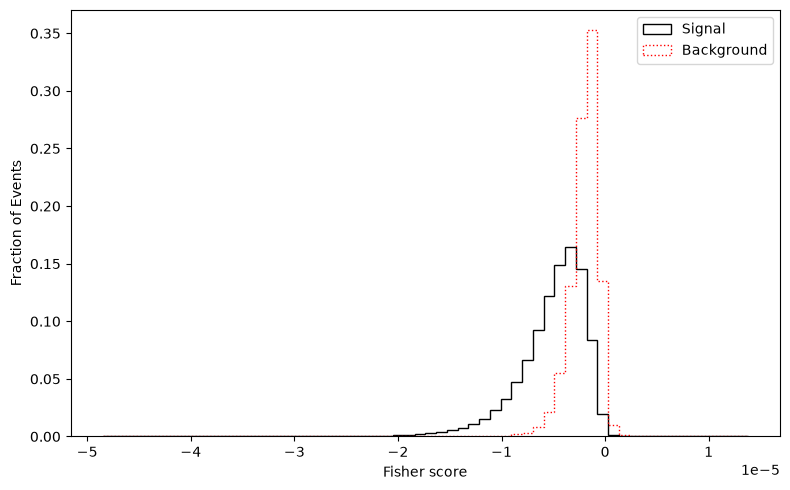

In [57]:
# 8.2
w = np.linalg.solve(S_W, mean_difference)

print("Fisher coefficients:")
for i in range(len(all_names)):
    print(all_names[i], round(w[i], 6))

F_signal = signal_data @ w
F_background = background_data @ w

bins = np.histogram_bin_edges(
    np.concatenate([F_signal, F_background]),
    bins=60
)

plt.figure(figsize=(8, 5))

plt.hist(
    F_signal,
    bins=bins,
    weights=np.ones(len(F_signal)) / len(F_signal),
    histtype="step",
    color="black",
    label="Signal"
)

plt.hist(
    F_background,
    bins=bins,
    weights=np.ones(len(F_background)) / len(F_background),
    histtype="step",
    color="red",
    linestyle=":",
    label="Background"
)

plt.xlabel("Fisher score")
plt.ylabel("Fraction of Events")
plt.legend()
plt.tight_layout()
plt.show()

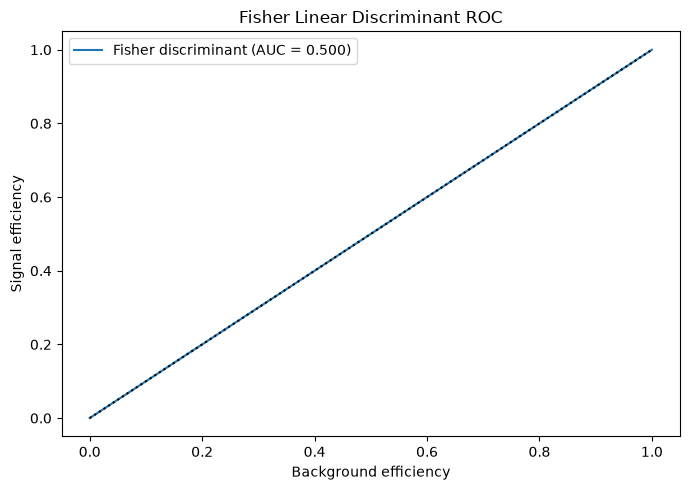

Fisher AUC: 0.5


In [58]:
# 8.3
if np.mean(F_signal) < np.mean(F_background):
    signal_scores = -F_signal
    background_scores = -F_background
else:
    signal_scores = F_signal
    background_scores = F_background

fpr_fisher, tpr_fisher = make_roc(
    signal_scores,
    background_scores
)

auc_fisher = np.trapezoid(tpr_fisher, fpr_fisher)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr_fisher,
    tpr_fisher,
    label="Fisher discriminant (AUC = {:.3f})".format(auc_fisher)
)

plt.plot([0, 1], [0, 1], "k:")
plt.xlabel("Background efficiency")
plt.ylabel("Signal efficiency")
plt.title("Fisher Linear Discriminant ROC")
plt.legend()
plt.tight_layout()
plt.show()

print("Fisher AUC:", round(auc_fisher, 3))

In [59]:
# 8.4
print("Maximum significance for each scenario:")

for n_signal, n_background in SCENARIOS:
    values = significance(
        tpr_fisher,
        fpr_fisher,
        n_signal,
        n_background
    )

    best_index = np.argmax(values)

    print(
        "NS =", n_signal,
        "NB =", n_background,
        "Maximum significance =",
        round(values[best_index], 3)
    )

Maximum significance for each scenario:
NS = 10 NB = 100 Maximum significance = 0.953
NS = 100 NB = 1000 Maximum significance = 3.015
NS = 1000 NB = 10000 Maximum significance = 9.535
NS = 10000 NB = 100000 Maximum significance = 30.151
